
# Online Shoppers Purchasing Intention Prediction

## Machine Learning Assignment 2

<p style="font-size:18px;">
<b>Student Name:</b> Pranali Laxman Patil
</p>

<p style="font-size:18px;">
<b>BITS ID:</b> 2026AJ05795
</p>

<p style="font-size:18px;">
<b>Semester:</b> 1st (2026-27)
</p>


**Problem Statement:**  
The objective is to predict whether an online shopping session will result in a purchase using machine learning classification models.

Five models will be implemented:
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

The models will be evaluated using Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC).


In [98]:

# Libraries for data handling
import pandas as pd
import numpy as np

# Libraries for plotting graphs
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries for splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Libraries for model evaluation
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Library for saving trained models
import joblib
import os

print("All libraries imported successfully!")


All libraries imported successfully!


In [99]:

def load_data(file_path):
    # Read the CSV file
    data = pd.read_csv(file_path, compression="infer")

    # Display the dataset size
    print("Dataset shape:", data.shape)

    # Return the loaded dataset
    return data


# URL of the dataset from UCI repository
dataset_url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"

# Load the dataset
df = load_data(dataset_url)

# Display first five rows
df.head()


Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [100]:

def explore_data(data):
    # Display basic dataset information
    print("Dataset Information:")
    data.info()

    # Check missing values
    print("\nMissing Values:")
    print(data.isnull().sum())

    # Check duplicate records
    print("\nDuplicate Rows:", data.duplicated().sum())

    # Display target class counts
    print("\nTarget Distribution:")
    print(data["Revenue"].value_counts())

    # Display summary statistics
    print("\nNumerical Summary:")
    display(data.describe())


# Explore the dataset
explore_data(df)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType 

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


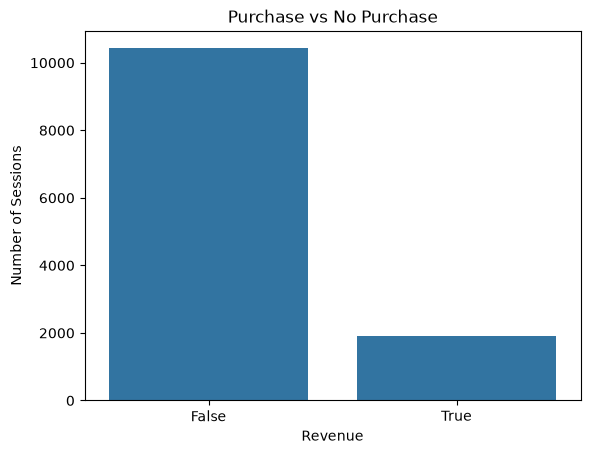

In [101]:

def plot_target_distribution(data):
    # Plot the count of each target class
    sns.countplot(data=data, x="Revenue")

    # Add labels and title
    plt.title("Purchase vs No Purchase")
    plt.xlabel("Revenue")
    plt.ylabel("Number of Sessions")

    # Display the graph
    plt.show()


# Plot the target distribution
plot_target_distribution(df)


In [102]:

def split_data(data):

    # Remove exact duplicate records
    clean_data = data.drop_duplicates().copy()

    print("Original records:", len(data))
    print("Records after removing duplicates:", len(clean_data))

    # Separate input features and target
    X = clean_data.drop(columns=["Revenue"])
    y = clean_data["Revenue"].astype(int)

    # Split into training and testing data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))

    return X_train, X_test, y_train, y_test


# Split the dataset again
X_train, X_test, y_train, y_test = split_data(df)


Original records: 12330
Records after removing duplicates: 12205
Training records: 9764
Testing records: 2441


In [103]:
def get_feature_types(X):
    # Identify categorical columns
    categorical_cols = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    # Identify numerical columns
    numerical_cols = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    return categorical_cols, numerical_cols


# Identify feature types from training data
categorical_cols, numerical_cols = get_feature_types(X_train)


C:\Users\Pranali\AppData\Local\Temp\ipykernel_29348\1468137789.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [104]:

# Columns that contain category codes
coded_categories = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

# Add these columns to categorical features
categorical_cols = list(dict.fromkeys(
    categorical_cols + coded_categories
))

# Remove these columns from numerical features
numerical_cols = [
    col for col in numerical_cols
    if col not in coded_categories
]

print("Categorical Features:", categorical_cols)
print("\nNumerical Features:", numerical_cols)

print("\nTotal Input Features:",
      len(categorical_cols) + len(numerical_cols))


Categorical Features: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Numerical Features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Total Input Features: 17



## Step 2: Data Preprocessing

The dataset contains both numerical and categorical features.

The following preprocessing techniques are used:

1. StandardScaler to scale numerical features.
2. OneHotEncoder to convert categorical features into numerical form.
3. ColumnTransformer to combine both preprocessing steps.

Preprocessing will be included in each model pipeline so that the same transformations are applied during training and testing.

The preprocessing steps will be fitted only on training data to avoid data leakage.


In [105]:

def create_preprocessor(numerical_cols, categorical_cols):

    # Scale numerical columns
    numerical_transformer = StandardScaler()

    # Encode categorical columns
    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

    # Combine both transformations
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, numerical_cols),
            ("cat", categorical_transformer, categorical_cols)
        ]
    )

    return preprocessor


# Create the preprocessing object
preprocessor = create_preprocessor(
    numerical_cols,
    categorical_cols
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [106]:

def check_preprocessor(preprocessor, X_train):

    # Get all columns used for preprocessing
    selected_columns = (
        numerical_cols + categorical_cols
    )

    # Check that all input columns are included
    missing_columns = set(X_train.columns) - set(selected_columns)

    # Check for repeated columns
    repeated_columns = len(selected_columns) != len(set(selected_columns))

    print("Original features:", X_train.shape[1])
    print("Selected features:", len(selected_columns))
    print("Missing features:", missing_columns)
    print("Repeated features:", repeated_columns)

    # Verify feature configuration
    assert len(missing_columns) == 0
    assert not repeated_columns
    assert len(selected_columns) == X_train.shape[1]

    print("\nPreprocessing configuration verified!")


# Check the preprocessing configuration
check_preprocessor(preprocessor, X_train)


Original features: 17
Selected features: 17
Missing features: set()
Repeated features: False

Preprocessing configuration verified!


In [107]:

def create_model_pipeline(model, numerical_cols, categorical_cols):

    # Create a new preprocessor for the model
    model_preprocessor = create_preprocessor(
        numerical_cols,
        categorical_cols
    )

    # Combine preprocessing and classification
    pipeline = Pipeline(steps=[
        ("preprocessor", model_preprocessor),
        ("classifier", model)
    ])

    return pipeline


print("Model pipeline function created successfully!")


Model pipeline function created successfully!



## Step 3: Model Training and Evaluation

Five classification algorithms are implemented on the same Online Shoppers dataset:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

All models use the same training and testing split for a fair comparison.

### Evaluation Metrics

The following metrics are calculated:
- Accuracy
- Area Under the ROC Curve (AUC)
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

Since the dataset has unequal class distribution, F1, Recall, MCC and AUC are also considered when comparing model performance.


In [108]:

def get_models():

    # Define all five classification models
    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

        "Decision Tree": DecisionTreeClassifier(
            random_state=42
        ),

        "KNN": KNeighborsClassifier(
            n_neighbors=5
        ),

        "Naive Bayes": GaussianNB(),

        "Support Vector Machine": SVC(
            kernel="rbf",
            random_state=42
        )
    }

    return models


# Get the classification models
models = get_models()

# Display model names
for name in models:
    print(name)


Logistic Regression
Decision Tree
KNN
Naive Bayes
Support Vector Machine


In [109]:

def train_model(model, X_train, y_train,
                numerical_cols, categorical_cols):

    # Create the preprocessing and model pipeline
    pipeline = create_model_pipeline(
        model,
        numerical_cols,
        categorical_cols
    )

    # Train the model on training data
    pipeline.fit(X_train, y_train)

    # Return the trained pipeline
    return pipeline


print("Training function created successfully!")


Training function created successfully!


In [110]:

def evaluate_model(model, X_test, y_test):

    # Predict target classes
    y_pred = model.predict(X_test)

    # Get probability or decision scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Calculate all six metrics
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    # Return only the metrics dictionary
    return metrics




print("Evaluation function created successfully!")


Evaluation function created successfully!


In [111]:

def save_model(model, file_name):

    # Create model folder if it does not exist
    os.makedirs("model", exist_ok=True)

    # Create the full file path
    file_path = os.path.join("model", file_name)

    # Save the trained pipeline
    joblib.dump(model, file_path)

    print("Saved:", file_path)


print("Model saving function created successfully!")


Model saving function created successfully!


In [112]:

# Store trained pipelines and evaluation results
trained_models = {}
evaluation_results = []

# File names for saved models
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Train and evaluate each model
for name, model in models.items():

    print("\nTraining:", name)

    # Train the model
    trained_pipeline = train_model(
        model,
        X_train,
        y_train,
        numerical_cols,
        categorical_cols
    )

    # Calculate all six evaluation metrics
    metrics = evaluate_model(
        trained_pipeline,
        X_test,
        y_test
    )

    # Store the model and its results
    trained_models[name] = trained_pipeline

    metrics["ML Model Name"] = name
    evaluation_results.append(metrics)

    # Save the trained pipeline
    save_model(
        trained_pipeline,
        model_files[name]
    )

    print("Completed:", name)

print("\nAll five models trained and evaluated!")



Training: Logistic Regression
Saved: model\logistic_regression.joblib
Completed: Logistic Regression

Training: Decision Tree
Saved: model\decision_tree.joblib
Completed: Decision Tree

Training: KNN
Saved: model\knn.joblib
Completed: KNN

Training: Naive Bayes
Saved: model\naive_bayes.joblib
Completed: Naive Bayes

Training: Support Vector Machine
Saved: model\svm.joblib
Completed: Support Vector Machine

All five models trained and evaluated!


In [113]:

# Convert model results into a DataFrame
comparison_df = pd.DataFrame(evaluation_results)

# Arrange columns as required in the assignment
comparison_df = comparison_df[
    [
        "ML Model Name",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1",
        "MCC"
    ]
]

# Display results rounded to four decimal places
display(comparison_df.round(4))


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8869,0.8996,0.7524,0.4136,0.5338,0.5032
1,Decision Tree,0.8566,0.7380,0.5400,0.5654,0.5524,0.4673
2,KNN,0.8734,0.7958,0.6622,0.3901,0.4909,0.4435
3,Naive Bayes,0.2773,0.7502,0.1756,0.9791,0.2978,0.1375
4,Support Vector Machine,0.8955,0.8729,0.7361,0.5183,0.6083,0.5614


In [114]:

# Find the model with the highest F1 Score
best_index = comparison_df["F1"].idxmax()

# Get the best model details
best_model = comparison_df.loc[best_index]

print("Best Model:", best_model["ML Model Name"])
print("F1 Score:", round(best_model["F1"], 4))
print("AUC Score:", round(best_model["AUC"], 4))
print("MCC Score:", round(best_model["MCC"], 4))


Best Model: Support Vector Machine
F1 Score: 0.6083
AUC Score: 0.8729
MCC Score: 0.5614


In [115]:

# Save evaluation metrics to a CSV file
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


Model comparison saved successfully!


In [116]:

# Create a copy of the test features
test_data = X_test.copy()

# Add the actual target values
test_data["Revenue"] = y_test

# Save the test dataset without row indices
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test data saved successfully!")
print("Test data shape:", test_data.shape)

# Display the first five records
display(test_data.head())


Test data saved successfully!
Test data shape: (2441, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
11757,0,0.000000,0,0.0,12,482.500000,0.02,0.040000,0.0,0.0,Nov,1,2,1,10,Returning_Visitor,False,0
7022,2,287.200000,0,0.0,16,473.283333,0.00,0.002222,0.0,0.0,Oct,2,2,1,2,New_Visitor,True,0
7281,2,187.900000,4,100.1,29,2107.033333,0.00,0.024242,0.0,0.0,Oct,1,1,3,1,Returning_Visitor,False,0
11373,7,280.266667,0,0.0,11,329.683333,0.00,0.023077,0.0,0.0,Dec,2,2,7,2,Returning_Visitor,False,0
4799,0,0.000000,0,0.0,5,0.000000,0.20,0.200000,0.0,0.0,May,3,2,5,6,Returning_Visitor,False,0


In [117]:

# Load the saved Logistic Regression pipeline
loaded_model = joblib.load(
    "model/logistic_regression.joblib"
)

# Predict using the saved model
loaded_predictions = loaded_model.predict(X_test)

# Compare predictions with the original model
original_predictions = trained_models[
    "Logistic Regression"
].predict(X_test)

# Verify both predictions are identical
assert np.array_equal(
    loaded_predictions,
    original_predictions
)

print("Saved model loaded successfully!")
print("Predictions match the original model.")


Saved model loaded successfully!
Predictions match the original model.


In [118]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Configure the application
st.set_page_config(
    page_title="Shopper Insight Lab",
    page_icon="🛒",
    layout="wide"
)


st.markdown("""
<style>
.block-container {
    padding-top: 2rem;
}

/* Style headings */
h1, h2, h3 {
    color: #20BFA9;
}

/* Style metric cards */
[data-testid="stMetric"] {
    background-color: #17332F;
    padding: 15px;
    border-radius: 10px;
    border: 1px solid #28665B;
}

/* Make metric labels visible */
[data-testid="stMetricLabel"] {
    color: #D4F5EB;
}

/* Make metric values visible */
[data-testid="stMetricValue"] {
    color: #FFFFFF;
}

</style>
""", unsafe_allow_html=True)


# Define the saved model paths
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Get the folder containing this application
BASE_DIR = os.path.dirname(os.path.abspath(__file__))


@st.cache_resource
def load_model(model_name):
    # Get the selected model file
    file_name = MODEL_FILES[model_name]

    # Build the complete model path
    model_path = os.path.join(
        BASE_DIR, "model", file_name
    )

    # Load the saved preprocessing and model pipeline
    return joblib.load(model_path)


def load_test_data(uploaded_file):
    # Read the uploaded test dataset
    return pd.read_csv(uploaded_file)


def validate_test_data(data, model):
    # Get the features expected by the trained model
    required_cols = list(model.feature_names_in_)

    # Check for missing input columns
    missing_cols = [
        col for col in required_cols
        if col not in data.columns
    ]

    # Check that the target column exists
    if "Revenue" not in data.columns:
        st.error("Target column 'Revenue' is missing.")
        return None, None

    if missing_cols:
        st.error(f"Missing input features: {missing_cols}")
        return None, None

    # Reject missing values in required columns
    if data[required_cols + ["Revenue"]].isnull().any().any():
        st.error("Test data contains missing values.")
        return None, None

    # Separate input features and target
    X_test = data[required_cols].copy()

    # Convert target values into 0 and 1
    target_values = data["Revenue"].astype(str).str.lower()

    if not target_values.isin(
        ["true", "false", "1", "0"]
    ).all():
        st.error("Revenue must contain True/False or 1/0.")
        return None, None

    y_test = target_values.map({
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    }).astype(int)

    return X_test, y_test



def evaluate_model(model, X_test, y_test):

    # Predict the target classes
    y_pred = model.predict(X_test)

    # Get scores for AUC calculation
    if hasattr(model, "predict_proba"):
        # Use probabilities for supported models
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        # Use decision scores for SVM
        y_score = model.decision_function(X_test)

    # Calculate all six evaluation metrics
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": (
            roc_auc_score(y_test, y_score)
            if y_test.nunique() == 2
            else np.nan
        ),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    return metrics, y_pred



def display_metrics(metrics):
    # Display metrics in two rows
    cols = st.columns(3)

    for i, name in enumerate(
        ["Accuracy", "AUC", "Precision"]
    ):
        cols[i].metric(name, f"{metrics[name]:.4f}")

    cols = st.columns(3)

    for i, name in enumerate(
        ["Recall", "F1", "MCC"]
    ):
        cols[i].metric(name, f"{metrics[name]:.4f}")



   


def plot_confusion_matrix(y_test, y_pred):

    # Calculate the confusion matrix
    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    # Labels for confusion matrix cells
    cell_labels = [
        ["TN", "FP"],
        ["FN", "TP"]
    ]

    # Create a customized heatmap
    fig = go.Figure(
        data=go.Heatmap(
            z=cm,
            x=["No Purchase", "Purchase"],
            y=["No Purchase", "Purchase"],
            colorscale=[
                [0, "#E4F5F0"],
                [0.5, "#5AC8AE"],
                [1, "#126B59"]
            ],
            showscale=True,
            hovertemplate=(
                "Actual: %{y}<br>"
                "Predicted: %{x}<br>"
                "Count: %{z}<extra></extra>"
            )
        )
    )

    # Display TN, FP, FN and TP with their counts
    for i in range(2):
        for j in range(2):
            fig.add_annotation(
                x=j,
                y=i,
                text=(
                    f"<b>{cell_labels[i][j]}</b>"
                    f"<br>{cm[i, j]}"
                ),
                showarrow=False,
                font=dict(
                    size=18,
                    color="black"
                )
            )

    # Customize the plot layout
    fig.update_layout(
        title="Confusion Matrix",
        xaxis_title="Predicted Class",
        yaxis_title="Actual Class",
        yaxis=dict(autorange="reversed"),
        height=400,
        margin=dict(
            l=20, r=20, t=50, b=30
        ),
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        font=dict(color="#FFFFFF")
    )

    # Display the interactive heatmap
    st.plotly_chart(
        fig,
        use_container_width=True
    )




def display_classification_report(y_test, y_pred):
    # Generate the classification report
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Purchase", "Purchase"],
        output_dict=True,
        zero_division=0
    )

    # Convert the report into a table
    report_df = pd.DataFrame(report).transpose()

    st.dataframe(
        report_df.round(4),
        use_container_width=True
    )


def compare_all_models(X_test, y_test):

    # Store evaluation results for all models
    results = []

    for model_name in MODEL_FILES:

        # Load the saved trained model
        model = load_model(model_name)

        # Calculate metrics on uploaded test data
        metrics, _ = evaluate_model(
            model, X_test, y_test
        )

        # Add model name to the results
        metrics["ML Model Name"] = model_name
        results.append(metrics)

    # Convert results into a comparison table
    comparison = pd.DataFrame(results)

    # Arrange columns
    comparison = comparison[
        [
            "ML Model Name",
            "Accuracy",
            "AUC",
            "Precision",
            "Recall",
            "F1",
            "MCC"
        ]
    ]

    return comparison



def main():
    # Application heading
    st.title("🛒 Shopper Insight Lab")
    st.write(
        "Evaluate machine learning models for "
        "online purchase intention prediction."
    )

    st.caption(
        "Dataset: UCI Online Shoppers Purchasing Intention"
    )

    st.divider()

    # Display application information
    with st.sidebar:
        st.header("About This Project")
        st.write("Classification Type: Binary")
        st.write("Input Features: 17")
        st.write("Target: Revenue")
        st.write("Models Available: 5")
        st.info(
            "Upload test data containing all input "
            "features and the Revenue target column."
        )

    # Upload test dataset
    st.subheader("1. Upload Test Dataset")

    uploaded_file = st.file_uploader(
        "Choose a CSV file",
        type=["csv"]
    )

    if uploaded_file is None:
        st.info("Upload test_data.csv to begin evaluation.")
        return

    try:
        test_data = load_test_data(uploaded_file)
    except Exception as error:
        st.error(f"Unable to read CSV: {error}")
        return

    st.success("Test dataset uploaded successfully!")

    # Show basic dataset information
    st.write("Number of test records:", len(test_data))

    with st.expander("Preview Uploaded Dataset"):
        st.dataframe(
            test_data.head(10),
            use_container_width=True
        )

    # Select the classification model
    st.subheader("2. Select Classification Model")

    model_name = st.selectbox(
        "Choose a trained model",
        list(MODEL_FILES.keys())
    )

    # Load the selected model
    try:
        model = load_model(model_name)
    except Exception as error:
        st.error(f"Unable to load model: {error}")
        return

    # Validate test dataset
    X_test, y_test = validate_test_data(
        test_data, model
    )

    if X_test is None:
        return

    # Evaluate the selected model
    try:
        metrics, y_pred = evaluate_model(
            model, X_test, y_test
        )
    except Exception as error:
        st.error(f"Evaluation failed: {error}")
        return

    # Display evaluation metrics
    st.subheader("3. Model Evaluation Results")
    st.write("Selected Model:", model_name)

    display_metrics(metrics)

    if np.isnan(metrics["AUC"]):
        st.warning(
            "AUC is unavailable because the uploaded "
            "test data contains only one target class."
        )

    st.divider()

    # Display confusion matrix and classification report
    st.subheader("4. Classification Performance")

    left, right = st.columns(2)

    with left:
        st.write("**Confusion Matrix**")
        plot_confusion_matrix(y_test, y_pred)

    with right:
        st.write("**Classification Report**")
        display_classification_report(
            y_test, y_pred
        )

    # Show actual and predicted values
    with st.expander("View Actual vs Predicted Results"):
        results = pd.DataFrame({
            "Actual Revenue": y_test.to_numpy(),
            "Predicted Revenue": y_pred
        })

        st.dataframe(
            results.head(100),
            use_container_width=True
        )

    
    # Compare all five models on the uploaded test data
    st.divider()
    st.subheader("5. Comparison of All Models")

    comparison = compare_all_models(X_test, y_test)

    # Display the comparison table
    st.dataframe(
        comparison.round(4),
        use_container_width=True
    )

    # Identify the model with the highest F1 score
    best_index = comparison["F1"].idxmax()
    best_name = comparison.loc[
        best_index, "ML Model Name"
    ]

    st.success(
        f"Highest F1 Score: {best_name}"
    )
    

    st.caption(
        "Predictions are generated using saved "
        "trained pipelines. No model retraining "
        "is performed on uploaded test data."
    )


if __name__ == "__main__":
    main()


Overwriting app.py


In [119]:

%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
plotly


Overwriting requirements.txt


In [120]:

# Check the files required for Streamlit
required_files = [
    "app.py",
    "requirements.txt",
    "test_data.csv",
    "model/logistic_regression.joblib",
    "model/decision_tree.joblib",
    "model/knn.joblib",
    "model/naive_bayes.joblib",
    "model/svm.joblib"
]

# Check each file
for file in required_files:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)


FOUND: app.py
FOUND: requirements.txt
FOUND: test_data.csv
FOUND: model/logistic_regression.joblib
FOUND: model/decision_tree.joblib
FOUND: model/knn.joblib
FOUND: model/naive_bayes.joblib
FOUND: model/svm.joblib


In [121]:

# Check installed package versions
import sklearn
import streamlit
import pandas
import numpy
import joblib
import matplotlib
import seaborn

packages = {
    "streamlit": streamlit.__version__,
    "pandas": pandas.__version__,
    "numpy": numpy.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__
}

# Display the installed versions
for package, version in packages.items():
    print(package, ":", version)


streamlit : 1.58.0
pandas : 3.0.3
numpy : 2.4.6
scikit-learn : 1.9.0
joblib : 1.5.3
matplotlib : 3.11.0
seaborn : 0.13.2


In [122]:

import subprocess
import sys

# Start Streamlit in the background
log_file = open("streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        "app.py",
        "--server.headless=true",
        "--server.port=8501"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

log_file.close()

print("Streamlit started. Process ID:", streamlit_process.pid)


# Check whether Streamlit is running
status = streamlit_process.poll()

if status is None:
    print("Streamlit is running successfully!")
else:
    print("Streamlit stopped with exit code:", status)

# Display Streamlit logs
with open("streamlit.log", "r") as file:
    print(file.read())



Streamlit started. Process ID: 40780
Streamlit is running successfully!



In [123]:

# Check for identical rows across training and test sets
train_rows = pd.util.hash_pandas_object(
    X_train, index=False
)

test_rows = pd.util.hash_pandas_object(
    X_test, index=False
)

overlapping_rows = test_rows.isin(set(train_rows)).sum()

print("Identical feature rows in train and test:", overlapping_rows)


Identical feature rows in train and test: 0


In [124]:

# Save the package versions used in the project
import streamlit
import pandas
import numpy
import sklearn
import joblib
import matplotlib
import seaborn

requirements = [
    f"streamlit=={streamlit.__version__}",
    f"pandas=={pandas.__version__}",
    f"numpy=={numpy.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"seaborn=={seaborn.__version__}"
]

# Write requirements to file
with open("requirements.txt", "w") as file:
    file.write("\n".join(requirements) + "\n")

print("requirements.txt updated successfully!")

for package in requirements:
    print(package)


requirements.txt updated successfully!
streamlit==1.58.0
pandas==3.0.3
numpy==2.4.6
scikit-learn==1.9.0
joblib==1.5.3
matplotlib==3.11.0
seaborn==0.13.2


In [125]:

# Check all files required for GitHub
required_files = [
    "app.py",
    "requirements.txt",
    "test_data.csv",
    "model_comparison.csv",
    "model/logistic_regression.joblib",
    "model/decision_tree.joblib",
    "model/knn.joblib",
    "model/naive_bayes.joblib",
    "model/svm.joblib"
]

# Display file status
for file_name in required_files:
    if os.path.isfile(file_name):
        print("FOUND:", file_name)
    else:
        print("MISSING:", file_name)


FOUND: app.py
FOUND: requirements.txt
FOUND: test_data.csv
FOUND: model_comparison.csv
FOUND: model/logistic_regression.joblib
FOUND: model/decision_tree.joblib
FOUND: model/knn.joblib
FOUND: model/naive_bayes.joblib
FOUND: model/svm.joblib


In [126]:
display(comparison_df.round(4))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8869,0.8996,0.7524,0.4136,0.5338,0.5032
1,Decision Tree,0.8566,0.7380,0.5400,0.5654,0.5524,0.4673
2,KNN,0.8734,0.7958,0.6622,0.3901,0.4909,0.4435
3,Naive Bayes,0.2773,0.7502,0.1756,0.9791,0.2978,0.1375
4,Support Vector Machine,0.8955,0.8729,0.7361,0.5183,0.6083,0.5614
